## Importing libraries

In [1]:
import tensorflow as tf
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

import streamlit as st
import sklearn
import numpy as np


## Data preprocessing

### Training image preprocessing

In [2]:
training_set = tf.keras.utils.image_dataset_from_directory(
   'train',
    labels="inferred",
    label_mode="categorical",
    class_names=None,
    color_mode="rgb",
    batch_size=32,
    image_size=(128, 128),
    shuffle=True,
    seed=None,
    validation_split=None,
    subset=None,
    interpolation="bilinear",
    follow_links=False,
    crop_to_aspect_ratio=False,
    pad_to_aspect_ratio=False,
    verbose=True,
)


Found 70295 files belonging to 38 classes.


### Validation image preprocessing 

In [3]:
validation_set = tf.keras.utils.image_dataset_from_directory(
   'valid',
    labels="inferred",
    label_mode="categorical",
    class_names=None,
    color_mode="rgb",
    batch_size=32,
    image_size=(128, 128),
    shuffle=True,
    seed=None,
    validation_split=None,
    subset=None,
    interpolation="bilinear",
    follow_links=False,
    crop_to_aspect_ratio=False,
    pad_to_aspect_ratio=False,
    verbose=True,
)

Found 17572 files belonging to 38 classes.


In [4]:
training_set

<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 128, 128, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 38), dtype=tf.float32, name=None))>

In [5]:
# x is the input images 
#y is the output labels 
for x,y in training_set :
  print(x,x.shape)
  print(y, y.shape) 
  break

tf.Tensor(
[[[[177.5  171.5  175.5 ]
   [185.   179.   183.  ]
   [178.25 172.25 176.25]
   ...
   [154.   132.   134.  ]
   [146.   124.   126.  ]
   [147.5  125.5  127.5 ]]

  [[178.5  172.5  176.5 ]
   [178.25 172.25 176.25]
   [179.   173.   177.  ]
   ...
   [153.75 131.75 133.75]
   [155.5  133.5  135.5 ]
   [146.5  124.5  126.5 ]]

  [[175.75 169.75 173.75]
   [182.25 176.25 180.25]
   [183.25 177.25 181.25]
   ...
   [148.25 126.25 128.25]
   [147.5  125.5  127.5 ]
   [156.   134.   136.  ]]

  ...

  [[189.   180.   185.  ]
   [184.   175.   180.  ]
   [186.   177.   182.  ]
   ...
   [168.   146.   148.  ]
   [162.25 140.25 142.25]
   [166.75 144.75 146.75]]

  [[192.   183.   188.  ]
   [189.   180.   185.  ]
   [193.5  184.5  189.5 ]
   ...
   [166.   144.   146.  ]
   [165.75 143.75 145.75]
   [172.   150.   152.  ]]

  [[185.25 176.25 181.25]
   [188.75 179.75 184.75]
   [185.   176.   181.  ]
   ...
   [164.25 142.25 144.25]
   [169.25 147.25 149.25]
   [162.5  140.5  14

## Building Model

In [6]:
from tensorflow.keras.layers import Dense, Conv2D , MaxPool2D, Flatten, Dropout
from tensorflow.keras.models import Sequential


In [7]:
model = Sequential()

### Building Convolution Layer

In [8]:
model.add(Conv2D(filters=32,kernel_size=3,padding='same',activation='relu',input_shape=[128,128,3]))
model.add(Conv2D(filters=32,kernel_size=3,activation='relu'))
model.add(MaxPool2D(pool_size=2, strides =2))

C:\Users\samak\miniconda3\envs\tf_env\lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [9]:
model.add(Conv2D(filters=64,kernel_size=3,padding='same',activation='relu'))
model.add(Conv2D(filters=64,kernel_size=3,activation='relu'))
model.add(MaxPool2D(pool_size=2, strides =2))

In [10]:
model.add(Conv2D(filters=128,kernel_size=3,padding='same',activation='relu'))
model.add(Conv2D(filters=128,kernel_size=3,activation='relu'))
model.add(MaxPool2D(pool_size=2, strides =2))

In [11]:
model.add(Conv2D(filters=256,kernel_size=3,padding='same',activation='relu'))
model.add(Conv2D(filters=256,kernel_size=3,activation='relu'))
model.add(MaxPool2D(pool_size=2, strides =2))

In [12]:
model.add(Conv2D(filters=512,kernel_size=3,padding='same',activation='relu'))
model.add(Conv2D(filters=512,kernel_size=3,activation='relu'))
model.add(MaxPool2D(pool_size=2, strides =2))

In [13]:
model.add(Dropout(0.25))

In [14]:
model.add(Flatten())

In [15]:
model.add(Dense(units=1500,activation ='relu'))

In [16]:
model.add(Dropout(0.4))

In [17]:
#output layer
model.add(Dense(units=38,activation='softmax'))

### Compiling Model

In [18]:
#Adjust learning rate if: Loss is not decreasing → reduce LR. or Training is too slow → increase LR.

model.compile(optimizer=tf.keras.optimizers.Adam(
    learning_rate=0.0001,
    beta_1=0.9,
    beta_2=0.999,
    epsilon=1e-07,
    amsgrad=False,
    weight_decay=None,
    clipnorm=None,
    clipvalue=None,
    global_clipnorm=None,
    use_ema=False,
    ema_momentum=0.99,
    ema_overwrite_frequency=None,
    loss_scale_factor=None,
    gradient_accumulation_steps=None,
    name='adam'
),loss='categorical_crossentropy',metrics=['accuracy'])

In [19]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 128, 128, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 126, 126, 32)        │           9,248 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 63, 63, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 63, 63, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 61, 61, 64)          │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 30, 30, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_4 (Conv2D)                    │ (None, 30, 30, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_5 (Conv2D)                    │ (None, 28, 28, 128)         │         147,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 14, 14, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_6 (Conv2D)                    │ (None, 14, 14, 256)         │         295,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_7 (Conv2D)                    │ (None, 12, 12, 256)         │         590,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 6, 6, 256)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_8 (Conv2D)                    │ (None, 6, 6, 512)           │       1,180,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_9 (Conv2D)                    │ (None, 4, 4, 512)           │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_4 (MaxPooling2D)       │ (None, 2, 2, 512)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 2, 2, 512)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 2048)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 1500)                │       3,073,500 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 1500)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 38)                  │          57,038 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 7,842,762 (29.92 MB)

 Trainable params: 7,842,762 (29.92 MB)

 Non-trainable params: 0 (0.00 B)

## Model training

In [20]:
from tensorflow.keras.callbacks import ModelCheckpoint

In [21]:
checkpoint = ModelCheckpoint(
    filepath="best_model.h5",
    monitor="val_accuracy",
    save_best_only=True,
    mode="max",
    verbose=1
)

training_history= model.fit(x=training_set, validation_data = validation_set, epochs = 10, callbacks=[checkpoint])

Epoch 1/10
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.3843 - loss: 2.1954
Epoch 1: val_accuracy improved from None to 0.82984, saving model to best_model.h5


2197/2197 ━━━━━━━━━━━━━━━━━━━━ 6323s 3s/step - accuracy: 0.5941 - loss: 1.3856 - val_accuracy: 0.8298 - val_loss: 0.5369
Epoch 2/10
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8363 - loss: 0.5209
Epoch 2: val_accuracy improved from 0.82984 to 0.91862, saving model to best_model.h5


2197/2197 ━━━━━━━━━━━━━━━━━━━━ 4949s 2s/step - accuracy: 0.8604 - loss: 0.4446 - val_accuracy: 0.9186 - val_loss: 0.2579
Epoch 3/10
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9049 - loss: 0.2964
Epoch 3: val_accuracy improved from 0.91862 to 0.92329, saving model to best_model.h5


2197/2197 ━━━━━━━━━━━━━━━━━━━━ 6981s 3s/step - accuracy: 0.9150 - loss: 0.2642 - val_accuracy: 0.9233 - val_loss: 0.2395
Epoch 4/10
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9363 - loss: 0.1945
Epoch 4: val_accuracy improved from 0.92329 to 0.94002, saving model to best_model.h5


2197/2197 ━━━━━━━━━━━━━━━━━━━━ 6040s 3s/step - accuracy: 0.9419 - loss: 0.1785 - val_accuracy: 0.9400 - val_loss: 0.1810
Epoch 5/10
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9518 - loss: 0.1442
Epoch 5: val_accuracy improved from 0.94002 to 0.95447, saving model to best_model.h5


2197/2197 ━━━━━━━━━━━━━━━━━━━━ 4286s 2s/step - accuracy: 0.9552 - loss: 0.1341 - val_accuracy: 0.9545 - val_loss: 0.1463
Epoch 6/10
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9639 - loss: 0.1065
Epoch 6: val_accuracy did not improve from 0.95447
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 4195s 2s/step - accuracy: 0.9650 - loss: 0.1051 - val_accuracy: 0.9487 - val_loss: 0.1638
Epoch 7/10
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9709 - loss: 0.0874
Epoch 7: val_accuracy improved from 0.95447 to 0.96176, saving model to best_model.h5


2197/2197 ━━━━━━━━━━━━━━━━━━━━ 4184s 2s/step - accuracy: 0.9725 - loss: 0.0842 - val_accuracy: 0.9618 - val_loss: 0.1283
Epoch 8/10
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9729 - loss: 0.0823
Epoch 8: val_accuracy did not improve from 0.96176
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 4181s 2s/step - accuracy: 0.9754 - loss: 0.0748 - val_accuracy: 0.9581 - val_loss: 0.1535
Epoch 9/10
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9788 - loss: 0.0644
Epoch 9: val_accuracy did not improve from 0.96176
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 4189s 2s/step - accuracy: 0.9798 - loss: 0.0612 - val_accuracy: 0.9595 - val_loss: 0.1435
Epoch 10/10
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9828 - loss: 0.0525
Epoch 10: val_accuracy did not improve from 0.96176
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 4180s 2s/step - accuracy: 0.9825 - loss: 0.0530 - val_accuracy: 0.9554 - val_loss: 0.1630


In [24]:
#load model in case of interruption (actually always coz sometimes the best model isn t the last (10 epoch)
from tensorflow.keras.models import load_model
model = load_model("best_model.h5")   # tu récupères ton meilleur modèle sauvegardé

model.compile(optimizer=tf.keras.optimizers.Adam(
    learning_rate=0.0001,
    beta_1=0.9,
    beta_2=0.999,
    epsilon=1e-07,
    amsgrad=False,
    weight_decay=None,
    clipnorm=None,
    clipvalue=None,
    global_clipnorm=None,
    use_ema=False,
    ema_momentum=0.99,
    ema_overwrite_frequency=None,
    loss_scale_factor=None,
    gradient_accumulation_steps=None,
    name='adam'
),loss='categorical_crossentropy',metrics=['accuracy'])


## Model Evaluation

In [25]:
#model evaluation on training set 
train_loss, train_acc = model.evaluate(training_set)

2197/2197 ━━━━━━━━━━━━━━━━━━━━ 2558s 1s/step - accuracy: 0.9872 - loss: 0.0390


In [26]:
print(train_loss, train_acc)

0.038991060107946396 0.9872252941131592


In [27]:
#model evaluation on validation set 
val_loss, val_acc = model.evaluate(validation_set)

550/550 ━━━━━━━━━━━━━━━━━━━━ 585s 1s/step - accuracy: 0.9618 - loss: 0.1283


In [28]:
print(val_loss, val_acc)

0.12828181684017181 0.9617573618888855


## Saving Model

In [29]:
#model.save("plant_disease_model.h5")
# also this coz it s easy to transfer to someone else ==> it s compressed 
model.save("plant_disease_model.keras")


In [30]:
#to visualise all the values 
training_history.history

{'accuracy': [0.5940536260604858,
  0.8603599071502686,
  0.9149868488311768,
  0.9419162273406982,
  0.9552315473556519,
  0.9649761915206909,
  0.9724873900413513,
  0.9754036664962769,
  0.9797852039337158,
  0.9824596047401428],
 'loss': [1.3855996131896973,
  0.4446392059326172,
  0.2642481029033661,
  0.17848895490169525,
  0.1341489553451538,
  0.10507077723741531,
  0.08418634533882141,
  0.07480651140213013,
  0.061249904334545135,
  0.05302714183926582],
 'val_accuracy': [0.8298429250717163,
  0.9186205267906189,
  0.923287034034729,
  0.9400182366371155,
  0.9544730186462402,
  0.9487252235412598,
  0.9617573618888855,
  0.9580582976341248,
  0.9594810009002686,
  0.9553835391998291],
 'val_loss': [0.5368767976760864,
  0.25785118341445923,
  0.23953674733638763,
  0.18097637593746185,
  0.14632190763950348,
  0.163803830742836,
  0.1282818466424942,
  0.15348471701145172,
  0.14347945153713226,
  0.16304956376552582]}

In [31]:
#recording Model History in json
import json
with open ("training_his.json", "w") as f : 
    json.dump(training_history.history,f)

### Accuracy visualisation

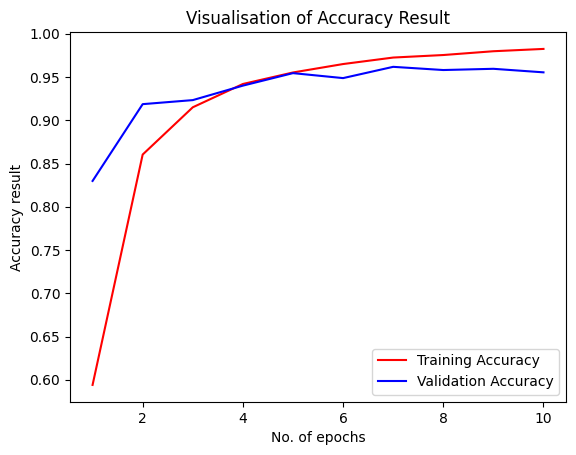

In [32]:
epochs = [i for i in range (1,11)]
plt.plot(epochs,training_history.history['accuracy'],color='red',label='Training Accuracy')
plt.plot(epochs,training_history.history['val_accuracy'],color='blue',label='Validation Accuracy')
plt.xlabel("No. of epochs")
plt.ylabel("Accuracy result")
plt.title("Visualisation of Accuracy Result")
plt.legend()
plt.show()

### Some other metrics for model evaluation

In [33]:
class_name = validation_set.class_names
class_name

['Apple___Apple_scab',
 'Apple___Black_rot',
 'Apple___Cedar_apple_rust',
 'Apple___healthy',
 'Blueberry___healthy',
 'Cherry_(including_sour)___Powdery_mildew',
 'Cherry_(including_sour)___healthy',
 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot',
 'Corn_(maize)___Common_rust_',
 'Corn_(maize)___Northern_Leaf_Blight',
 'Corn_(maize)___healthy',
 'Grape___Black_rot',
 'Grape___Esca_(Black_Measles)',
 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)',
 'Grape___healthy',
 'Orange___Haunglongbing_(Citrus_greening)',
 'Peach___Bacterial_spot',
 'Peach___healthy',
 'Pepper,_bell___Bacterial_spot',
 'Pepper,_bell___healthy',
 'Potato___Early_blight',
 'Potato___Late_blight',
 'Potato___healthy',
 'Raspberry___healthy',
 'Soybean___healthy',
 'Squash___Powdery_mildew',
 'Strawberry___Leaf_scorch',
 'Strawberry___healthy',
 'Tomato___Bacterial_spot',
 'Tomato___Early_blight',
 'Tomato___Late_blight',
 'Tomato___Leaf_Mold',
 'Tomato___Septoria_leaf_spot',
 'Tomato___Spider_mites Two-spotted_

In [35]:
test_set = tf.keras.utils.image_dataset_from_directory(
   'valid',
    labels="inferred",
    label_mode="categorical",
    class_names=None,
    color_mode="rgb",
    batch_size=32,
    image_size=(128, 128),
    shuffle=False,
    seed=None,
    validation_split=None,
    subset=None,
    interpolation="bilinear",
    follow_links=False,
    crop_to_aspect_ratio=False,
    pad_to_aspect_ratio=False,
    verbose=True,
)

Found 17572 files belonging to 38 classes.


In [36]:
y_pred = model.predict(test_set)
y_pred,y_pred.shape

550/550 ━━━━━━━━━━━━━━━━━━━━ 511s 929ms/step


(array([[9.9995518e-01, 2.2564520e-05, 5.1025889e-08, ..., 1.2097037e-11,
         5.6003362e-12, 6.3666783e-10],
        [9.9991524e-01, 6.0362756e-05, 3.7174175e-08, ..., 2.4504007e-10,
         3.0591082e-11, 4.1604977e-09],
        [9.9999940e-01, 1.3579167e-07, 6.9390635e-09, ..., 6.1258595e-14,
         2.6105596e-13, 2.9151383e-11],
        ...,
        [2.8018348e-13, 2.0490258e-17, 9.6134548e-13, ..., 1.2220470e-15,
         1.3976765e-17, 1.0000000e+00],
        [3.1144968e-13, 3.0268644e-18, 5.0293596e-13, ..., 8.2746522e-16,
         3.0576778e-17, 1.0000000e+00],
        [3.0314980e-18, 1.4807301e-17, 3.3830197e-16, ..., 3.3636863e-19,
         1.3804562e-16, 1.0000000e+00]], shape=(17572, 38), dtype=float32),
 (17572, 38))

In [37]:
#To take only the maximum probability and also returns its index
# axis =1 means that we take the maximum in columns , if =0 then in rows 
predicted_categories = tf.argmax(y_pred,axis = 1)

In [38]:
predicted_categories

<tf.Tensor: shape=(17572,), dtype=int64, numpy=array([ 0,  0,  0, ..., 37, 37, 37], shape=(17572,))>

In [39]:
true_categories = tf.concat([y for x,y in test_set], axis=0)
true_categories

<tf.Tensor: shape=(17572, 38), dtype=float32, numpy=
array([[1., 0., 0., ..., 0., 0., 0.],
       [1., 0., 0., ..., 0., 0., 0.],
       [1., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 1.],
       [0., 0., 0., ..., 0., 0., 1.],
       [0., 0., 0., ..., 0., 0., 1.]], shape=(17572, 38), dtype=float32)>

In [40]:
Y_true = tf.argmax(y_pred,axis=1)
Y_true

<tf.Tensor: shape=(17572,), dtype=int64, numpy=array([ 0,  0,  0, ..., 37, 37, 37], shape=(17572,))>

In [41]:
from sklearn.metrics import classification_report, confusion_matrix

In [42]:
print(classification_report(Y_true,predicted_categories,target_names=class_name))

                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       1.00      1.00      1.00       515
                                 Apple___Black_rot       1.00      1.00      1.00       495
                          Apple___Cedar_apple_rust       1.00      1.00      1.00       437
                                   Apple___healthy       1.00      1.00      1.00       466
                               Blueberry___healthy       1.00      1.00      1.00       461
          Cherry_(including_sour)___Powdery_mildew       1.00      1.00      1.00       426
                 Cherry_(including_sour)___healthy       1.00      1.00      1.00       453
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot       1.00      1.00      1.00       362
                       Corn_(maize)___Common_rust_       1.00      1.00      1.00       472
               Corn_(maize)___Northern_Leaf_Blight       1.00      1.00      1.

In [43]:
cm=confusion_matrix(Y_true,predicted_categories)
cm.shape

(38, 38)

### Confusion matrix visualisation

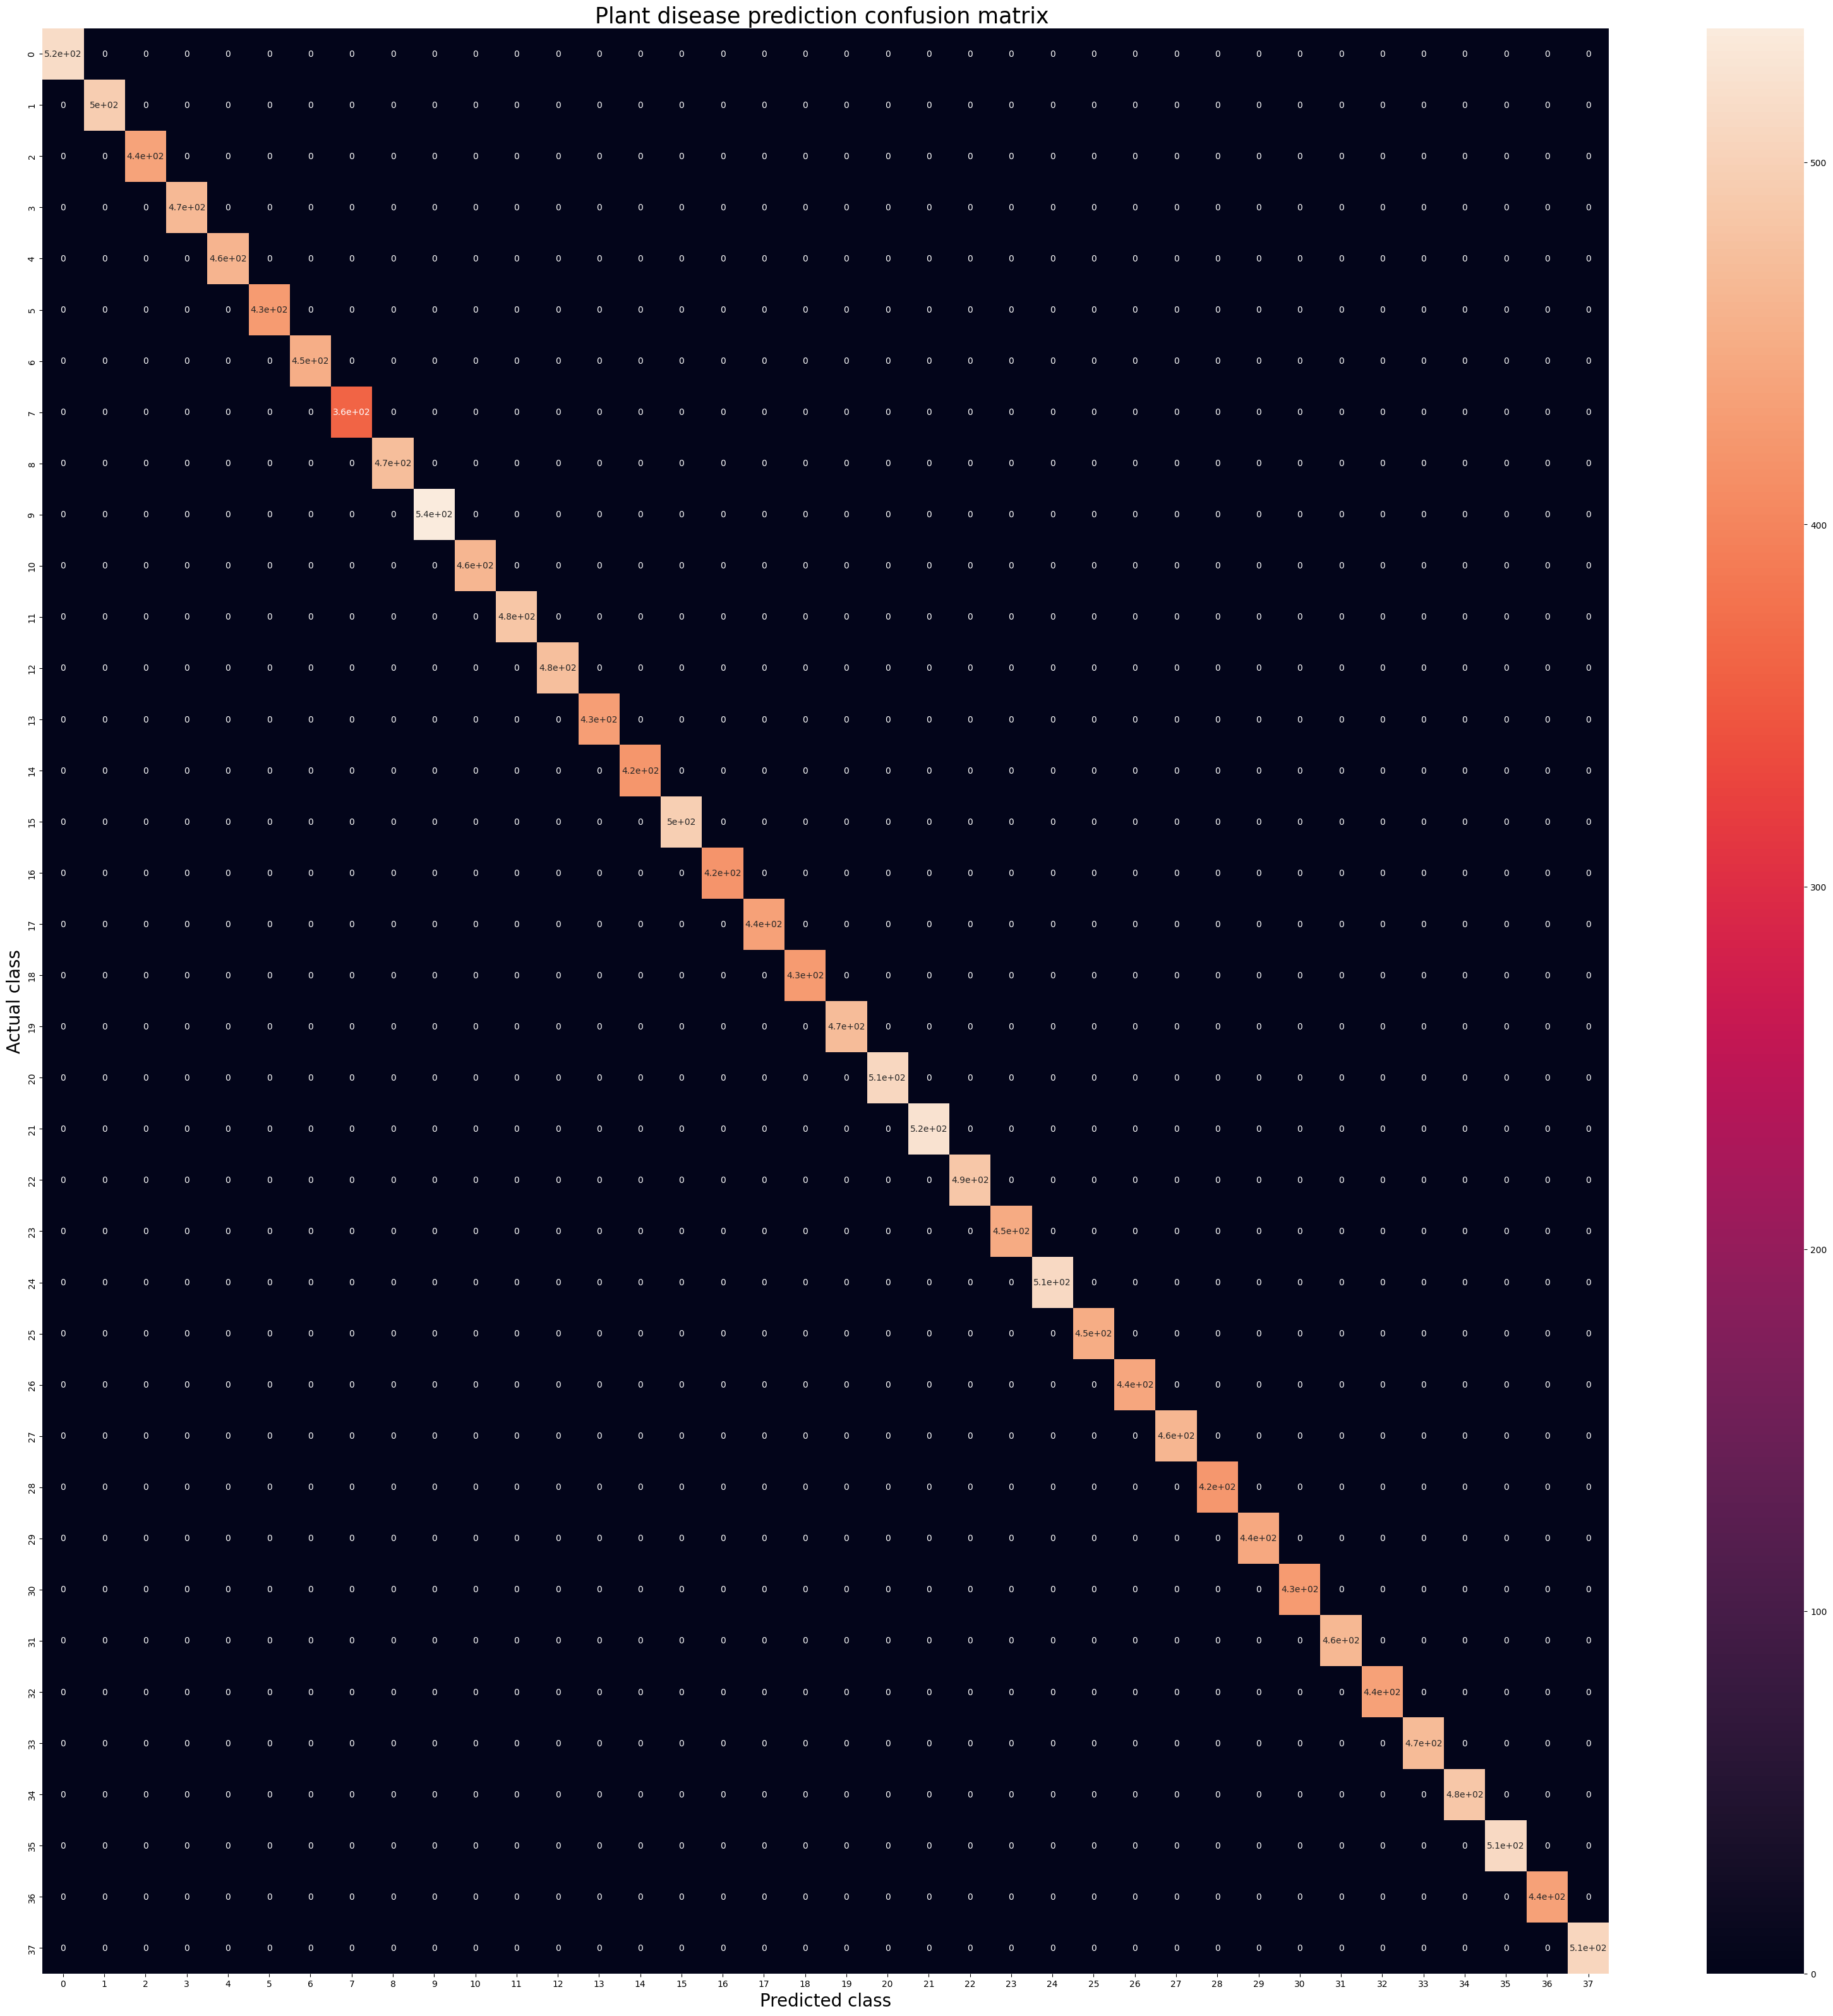

In [47]:
plt.figure(figsize =(40,40))
sns.heatmap(cm,annot=True, annot_kws={'size':10})
plt.xlabel("Predicted class",fontsize=20)
plt.ylabel("Actual class",fontsize=20)
plt.title("Plant disease prediction confusion matrix ",fontsize=25)
plt.show()

### Loading Model 

In [50]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [51]:
 model = tf.keras.models.load_model('plant_disease_model.keras')

C:\Users\samak\miniconda3\envs\tf_env\lib\site-packages\keras\src\saving\saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 50 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [52]:
model.summary

<bound method Model.summary of <Sequential name=sequential, built=True>>

### Visualizing single Image of test set 

In [53]:
!pip install opencv-python 

   ---------------------------------------- 0.0/39.0 MB ? eta -:--:--
   ---------------------------------------- 0.3/39.0 MB ? eta -:--:--
    --------------------------------------- 0.5/39.0 MB 1.9 MB/s eta 0:00:21
   - -------------------------------------- 1.0/39.0 MB 2.0 MB/s eta 0:00:19
   - -------------------------------------- 1.3/39.0 MB 1.6 MB/s eta 0:00:24
   - -------------------------------------- 1.6/39.0 MB 1.6 MB/s eta 0:00:24
   -- ------------------------------------- 2.1/39.0 MB 1.7 MB/s eta 0:00:22
   -- ------------------------------------- 2.4/39.0 MB 1.8 MB/s eta 0:00:21
   -- ------------------------------------- 2.6/39.0 MB 1.8 MB/s eta 0:00:21
   --- ------------------------------------ 3.1/39.0 MB 1.8 MB/s eta 0:00:20
   --- ------------------------------------ 3.4/39.0 MB 1.7 MB/s eta 0:00:22
   --- ------------------------------------ 3.7/39.0 MB 1.7 MB/s eta 0:00:22
   ---- ----------------------------------- 4.2/39.0 MB 1.7 MB/s eta 0:00:21
   ---- -----

In [56]:
import cv2

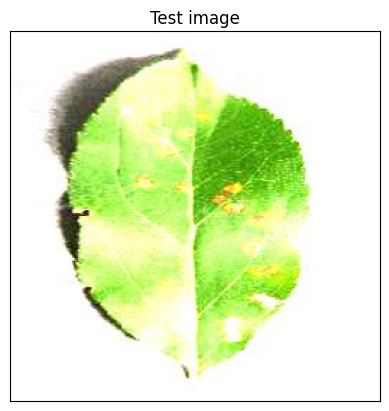

In [58]:
image_path = "test/test/AppleCedarRust1.JPG"
#Reading Image
img = cv2.imread(image_path)
img =cv2.cvtColor(img,cv2.COLOR_BGR2RGB) #convert bgr image to rgb
#displaying image 
plt.imshow(img)
plt.xticks([])#remove axis 
plt.yticks([]) # remove axis
plt.title("Test image")
plt.show()

### Testing Model

In [59]:
image =tf.keras.preprocessing.image.load_img(image_path,target_size =(128,128))
input_arr=tf.keras.preprocessing.image.img_to_array(image)
input_arr = np.array([input_arr]) # convert single image tp batch
print(input_arr)

[[[[255. 255. 255.]
   [255. 255. 255.]
   [255. 255. 255.]
   ...
   [255. 255. 255.]
   [255. 255. 255.]
   [255. 255. 255.]]

  [[255. 255. 255.]
   [255. 255. 255.]
   [255. 255. 255.]
   ...
   [255. 255. 255.]
   [255. 255. 255.]
   [255. 255. 255.]]

  [[255. 255. 255.]
   [255. 255. 255.]
   [255. 255. 255.]
   ...
   [255. 255. 255.]
   [255. 255. 255.]
   [255. 255. 255.]]

  ...

  [[255. 255. 255.]
   [255. 255. 255.]
   [255. 255. 255.]
   ...
   [255. 255. 255.]
   [255. 255. 255.]
   [255. 255. 255.]]

  [[255. 255. 255.]
   [255. 255. 255.]
   [255. 255. 255.]
   ...
   [255. 255. 255.]
   [255. 255. 255.]
   [255. 255. 255.]]

  [[255. 255. 255.]
   [255. 255. 255.]
   [255. 255. 255.]
   ...
   [255. 255. 255.]
   [255. 255. 255.]
   [255. 255. 255.]]]]


In [60]:
prediction = model.predict(input_arr)
prediction,prediction.shape

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 400ms/step


(array([[4.3846902e-15, 2.6201827e-18, 1.0000000e+00, 4.0299737e-17,
         9.0670906e-14, 2.3147557e-11, 1.7251752e-18, 7.6244204e-16,
         8.9641943e-21, 2.7276979e-19, 3.9145527e-21, 8.0669369e-12,
         1.1800147e-16, 5.9730736e-16, 3.0238639e-14, 3.6211024e-13,
         1.1130000e-16, 2.2137676e-17, 6.1779576e-15, 1.6525926e-13,
         2.5129234e-17, 6.0757909e-18, 5.4620757e-14, 8.5821177e-16,
         2.8082157e-18, 3.5430910e-15, 1.9146581e-17, 2.7162684e-17,
         1.0321145e-13, 4.1973074e-14, 1.8730182e-13, 2.0857268e-18,
         1.5844352e-15, 4.3680748e-17, 2.4049038e-12, 6.9141107e-13,
         3.3447290e-16, 8.0466707e-15]], dtype=float32),
 (1, 38))

In [61]:
result_index = np.argmax(prediction)

In [62]:
#displaying the result of disease prediction
model_prediction = class_name[result_index]
model_prediction

'Apple___Cedar_apple_rust'